# Pune Rental Market Analysis
**Business question:** Which Pune localities give the best value for a fresher / IT professional, and where are prices overheated?

> Data note: if `data/raw/pune_rental_raw.csv` is the simulated sample, findings below are illustrative only. Re-run on real listings before quoting numbers.

## 1. Load raw data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
raw = pd.read_csv("../data/raw/pune_rental_raw.csv")
print(raw.shape)
raw.head()

(6090, 13)


,listing_id,locality,bhk,area_sqft,furnishing,rent_inr,deposit_inr,floor,property_age_years,parking,property_type,listing_date,bathrooms
0,PUN105456,karve nagar,1,607 sq.ft,Semi-Furnished,15100,"Rs 45,300",11.0,15.0,Yes,Independent House,2025-08-05,NaN
1,PUN105348,Viman Nagar,2,832,Semi-Furnished,29600,"Rs 148,000",5.0,0.0,Yes,Builder Floor,2025-08-05,1.0
2,PUN102449,Baner,2,838 sq.ft,Semi-Furnished,28600,"Rs 143,000",8.0,15.0,No,Apartment,2025-02-16,1.0
3,PUN103909,Wakad,2,985,Semi-Furnished,27000,"Rs 81,000",18.0,18.0,No,Apartment,2025-01-25,2.0
4,PUN101208,Kalyani Nagar,1,644 sq.ft,Unfurnished,"₹ 25,500","Rs 153,000",8.0,0.0,Yes,Independent House,2025-04-15,1.0


## 2. Data quality check (before cleaning)

In [2]:
print("Duplicates:", raw.duplicated().sum())
print("\nMissing values:\n", raw.isna().sum()[lambda s: s > 0])
print("\nSample of messy text values:")
raw[["locality", "rent_inr", "area_sqft", "deposit_inr"]].sample(6, random_state=3)

Duplicates: 90

Missing values:
 furnishing            243
floor                 366
property_age_years    487
bathrooms             181
dtype: int64

Sample of messy text values:


,locality,rent_inr,area_sqft,deposit_inr
820,Aundh,"₹ 58,800",1453 sq.ft,"Rs 176,400"
2416,Viman Nagar,40400,1031 sq.ft,"Rs 202,000"
5988,Undri,"₹ 23,200",1384 sq.ft,"Rs 69,600"
5028,Hinjewadi,"₹ 31,000",1204,"Rs 124,000"
5104,Katraj,48500,2209 sq.ft,"Rs 242,500"
2678,Viman Nagar,"₹ 35,100",999 sq.ft,"Rs 105,300"


## 3. Cleaning
The full pipeline lives in `scripts/clean_data.py` (text standardisation, string-to-number conversion, de-duplication, missing-value treatment, IQR outlier removal, feature engineering). Cleaning log: `docs/cleaning_log.txt`.

In [3]:
df = pd.read_csv("../data/processed/pune_rental_clean.csv")
print(df.shape, "| missing cells:", df.isna().sum().sum())
df.describe().T[["mean", "min", "50%", "max"]].round(1)

(5929, 18) | missing cells: 0


,mean,min,50%,max
bhk,2.2,1.0,2.0,4.0
area_sqft,1072.5,450.0,984.0,2599.0
rent_inr,31199.4,6200.0,27900.0,122700.0
deposit_inr,119018.4,14200.0,101200.0,674400.0
floor,10.4,0.0,10.0,21.0
property_age_years,9.6,0.0,10.0,19.0
parking,0.7,0.0,1.0,1.0
bathrooms,1.8,1.0,2.0,4.0
rent_per_sqft,29.0,12.6,28.6,50.6
deposit_months,3.8,2.0,4.0,6.0


## 4. Rent per sq ft by locality

In [4]:
loc = df.groupby("locality").agg(avg_ppsf=("rent_per_sqft", "mean"), listings=("listing_id", "count")).sort_values("avg_ppsf", ascending=False).round(2)
city = df["rent_per_sqft"].mean()
loc["vs_city_%"] = ((loc["avg_ppsf"] / city - 1) * 100).round(1)
loc["segment"] = np.where(loc["avg_ppsf"] > city*1.15, "Premium", np.where(loc["avg_ppsf"] < city*0.85, "Value", "Mid-market"))
loc

,avg_ppsf,listings,vs_city_%,segment
locality,,,,
Koregaon Park,43.13,169,48.5,Premium
Kalyani Nagar,40.28,190,38.7,Premium
Aundh,36.97,278,27.3,Premium
Baner,36.08,362,24.2,Premium
Viman Nagar,35.37,341,21.8,Premium
Magarpatta,34.13,209,17.5,Premium
Kothrud,33.40,395,15.0,Mid-market
Kharadi,31.85,406,9.7,Mid-market
Bavdhan,29.96,193,3.1,Mid-market


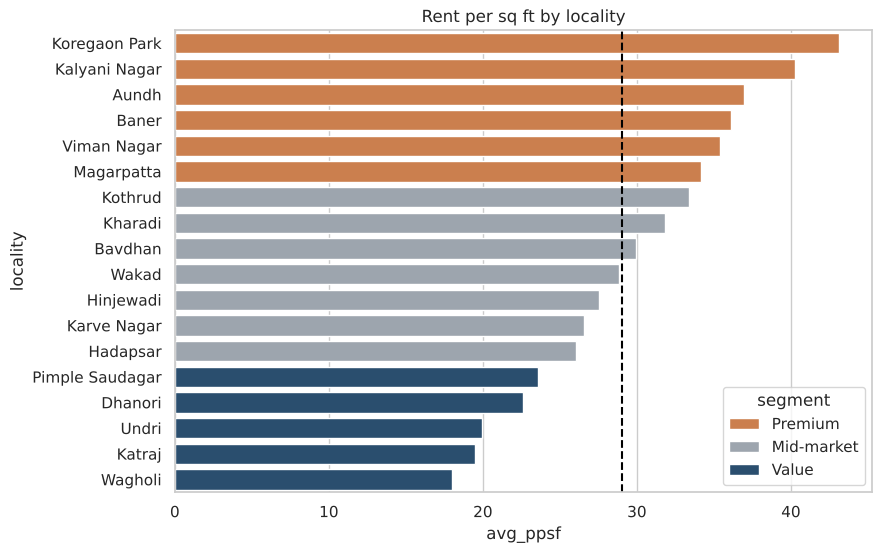

In [5]:
plt.figure(figsize=(9,6))
sns.barplot(data=loc.reset_index(), y="locality", x="avg_ppsf", hue="segment",
            palette={"Premium":"#e07b39","Mid-market":"#9aa5b1","Value":"#1f4e79"}, dodge=False)
plt.axvline(city, color="black", ls="--"); plt.title("Rent per sq ft by locality"); plt.show()

## 5. Furnishing premium and property age

In [6]:
f = df[df.furnishing != "Unknown"].groupby("furnishing")["rent_per_sqft"].mean()
print(f.round(2)); print("Furnished premium vs unfurnished: %.1f%%" % ((f["Furnished"]/f["Unfurnished"]-1)*100))
df.groupby(pd.cut(df.property_age_years, [-1,3,8,14,100], labels=["0-3","4-8","9-14","15+"]), observed=True)["rent_per_sqft"].mean().round(2)

furnishing
Furnished         32.01
Semi-Furnished    29.48
Unfurnished       26.58
Name: rent_per_sqft, dtype: float64
Furnished premium vs unfurnished: 20.4%


property_age_years
0-3     30.07
4-8     29.70
9-14    28.76
15+     28.05
Name: rent_per_sqft, dtype: float64

## 6. Heatmap: locality x BHK

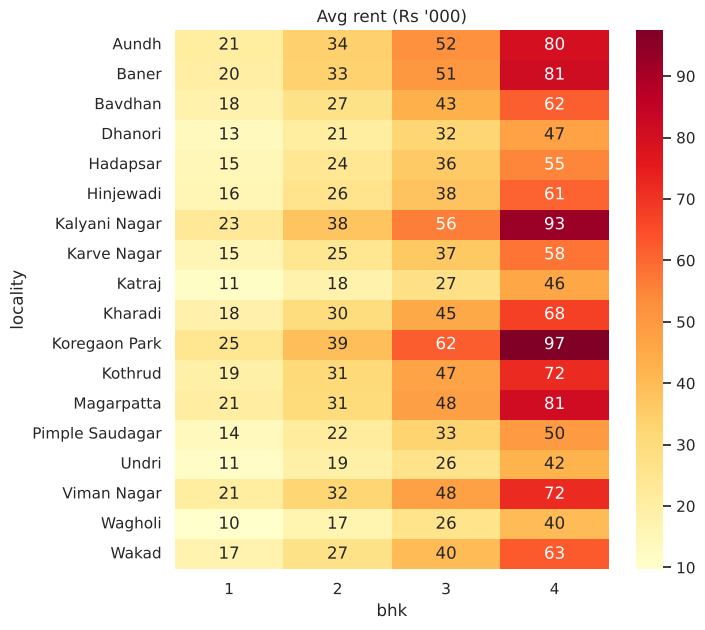

In [7]:
heat = df.pivot_table(index="locality", columns="bhk", values="rent_inr", aggfunc="mean")/1000
plt.figure(figsize=(7,7)); sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd"); plt.title("Avg rent (Rs '000)"); plt.show()

## 7. Budget finder for a fresher (1-2 BHK, up to Rs 25,000)

In [8]:
b = df[(df.bhk.isin([1,2])) & (df.rent_inr <= 25000)].groupby("locality").agg(options=("listing_id","count"), avg_rent=("rent_inr","mean"), avg_ppsf=("rent_per_sqft","mean")).round(0).sort_values("options", ascending=False)
b.head(8)

,options,avg_rent,avg_ppsf
locality,,,
Pimple Saudagar,238,18001.0,23.0
Hinjewadi,225,19420.0,26.0
Wagholi,212,14425.0,18.0
Wakad,198,19351.0,28.0
Katraj,191,15852.0,20.0
Hadapsar,186,19129.0,25.0
Karve Nagar,174,19171.0,26.0
Undri,160,16712.0,20.0


## 8. Monthly trend

In [9]:
m = df.groupby("listing_month").agg(avg_ppsf=("rent_per_sqft","mean"), listings=("listing_id","count")).round(2)
m["mom_%"] = (m.avg_ppsf.pct_change()*100).round(2)
m

,avg_ppsf,listings,mom_%
listing_month,,,
2025-01,28.86,475,NaN
2025-02,28.87,544,0.03
2025-03,29.14,505,0.94
2025-04,28.82,489,-1.10
2025-05,29.55,494,2.53
2025-06,29.01,458,-1.83
2025-07,28.48,491,-1.83
2025-08,28.88,489,1.40
2025-09,29.51,495,2.18


## 9. Findings and recommendations (fill with YOUR real-data results)
1. Premium vs value localities: ...
2. Furnishing premium: ...
3. Best-value areas for a fresher budget: ...
4. Seasonality / trend: ...
5. Recommendation: ...

Re-run `python scripts/eda_charts.py` and copy the numbers from `docs/insights_summary.md`.